# 03. Interpretasi Klaster dan Klasifikasi Red/Neutral/Blue Ocean
---

### **Tujuan Notebook:**
1. Memuat dataset terklasterisasi (`02_umkm_kmodes_clustered.csv`, $k=3$ final, 2 fitur) dari `02_kmodes_partitioning.ipynb` -- jumlah klaster ($k$) **sudah final** (murni dari kurva Elbow), notebook ini tidak menentukan $k$.
2. Menghasilkan tabulasi silang deskriptif profil dominan tiap klaster (kategori termayoritas + persentasenya per fitur, per wilayah) untuk $k$ final -- murni sebagai alat deskriptif untuk kartu profil klaster, bukan metrik validasi kuantitatif.
3. Menghitung Location Quotient (LQ) tiap klaster (dominan sektornya) terhadap rata-rata se-DKI Jakarta, lalu mengklasifikasikannya sebagai **Red Ocean** (LQ tinggi, kompetitif), **Neutral Ocean**, atau **Blue Ocean** (LQ rendah, kurang terwakili -- peluang).
4. Membandingkan profil klaster multivariat dengan distribusi frekuensi sederhana (`value_counts()`) untuk menunjukkan nilai tambah clustering 2 atribut.
5. Memvisualisasikan peta klaster (heatmap sektor × usia usaha) per wilayah.
6. Menghasilkan `profile_df` final -- lengkap dengan Location Quotient dan label Ocean per klaster -- siap dipakai `app.py` untuk kartu profil klaster, disimpan ke `data/processed/03_kmodes_evaluation_summary.csv`.

> **Catatan:** Notebook ini **tidak menghitung Purity Index/indeks dominansi kategori apa pun**. Metrik semacam itu secara akademis tidak tepat dipakai sebagai validasi kuantitatif karena dihitung dari atribut yang sama dipakai membentuk klaster (bukan label eksternal/ground truth), dan terbukti bias naik terus seiring bertambahnya $k$. Tabulasi silang di sini murni deskriptif (menjelaskan isi tiap klaster), dan pemilihan $k$ sudah final dari kurva Elbow di `02_kmodes_partitioning.ipynb`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

FEATURES = ['sektor_makro', 'kelompok_tahun_berdiri']

print("Pustaka interpretasi klaster sukses dimuat.")

Pustaka interpretasi klaster sukses dimuat.


## 1. Memuat Dataset Hasil Klasterisasi K-Modes ($k=3$ Final)
Kurva Elbow untuk pemilihan $k$ sudah dihitung tuntas di `02_kmodes_partitioning.ipynb` -- notebook ini hanya memuat hasil akhirnya ($k=3$, sudah final).

In [2]:
file_path = os.path.join('..', 'data', 'processed', '02_umkm_kmodes_clustered.csv')
if not os.path.exists(file_path):
    file_path = '02_umkm_kmodes_clustered.csv'

df = pd.read_csv(file_path)
daftar_wilayah = sorted(df['wilayah'].unique().tolist())
print(f"Dataset terklasterisasi berhasil dimuat: {len(df):,} baris.")

df[['wilayah'] + FEATURES + ['cluster']].head(5)

Dataset terklasterisasi berhasil dimuat: 266,678 baris.


,wilayah,sektor_makro,kelompok_tahun_berdiri,cluster
0,KAB. ADM. KEP. SERIBU,"Jasa, Teknologi & Otomotif",Usaha Lama (2020-2021),0
1,KAB. ADM. KEP. SERIBU,Fesyen & Industri Tekstil,Usaha Lama (2020-2021),0
2,KAB. ADM. KEP. SERIBU,Kuliner & Pangan Olahan,Usaha Berkembang (2022-2023),2
3,KAB. ADM. KEP. SERIBU,"Jasa, Teknologi & Otomotif",Usaha Lama (2020-2021),0
4,KAB. ADM. KEP. SERIBU,Kuliner & Pangan Olahan,Usaha Berkembang (2022-2023),2


In [3]:
def profil_dominan_klaster(sub, features, cluster_col='cluster'):
    """Tabulasi silang deskriptif: kategori termayoritas beserta persentasenya pada
    tiap fitur, di tiap klaster. Murni alat deskriptif untuk kartu profil klaster --
    BUKAN metrik validasi kuantitatif (tidak dipakai untuk menentukan k)."""
    n_total = len(sub)
    profile_rows = []
    for cl, c in sub.groupby(cluster_col):
        row = {'cluster': cl, 'n': len(c), 'pct_n': len(c) / n_total * 100}
        for f in features:
            vc = c[f].value_counts(normalize=True)
            row[f'{f}_dominan'] = vc.idxmax()
            row[f'{f}_pct'] = vc.max() * 100
        profile_rows.append(row)
    return pd.DataFrame(profile_rows)

## 2. Profil Klaster Final ($k=3$) -- Tabulasi Silang Deskriptif per Klaster per Wilayah
Tabulasi silang ringkas: untuk tiap klaster hasil model produksi ($k=3$, `02_umkm_kmodes_clustered.csv`), ditampilkan kategori termayoritas pada tiap fitur beserta persentasenya. Murni deskriptif -- dipakai untuk menyusun kartu profil klaster, bukan sebagai metrik validasi kuantitatif.

In [4]:
profile_list = []

print("=== PROFIL KLASTER FINAL (k=3) PER WILAYAH (TABULASI SILANG DESKRIPTIF) ===")
for wil in daftar_wilayah:
    df_wil = df[df['wilayah'] == wil]
    profile_wil = profil_dominan_klaster(df_wil, FEATURES)
    profile_wil.insert(0, 'wilayah', wil)
    profile_list.append(profile_wil)
    print(f"\n--- {wil} ---")
    print(profile_wil.to_string(index=False))

profile_df = pd.concat(profile_list, ignore_index=True)

=== PROFIL KLASTER FINAL (k=3) PER WILAYAH (TABULASI SILANG DESKRIPTIF) ===

--- KAB. ADM. KEP. SERIBU ---
              wilayah  cluster    n     pct_n           sektor_makro_dominan  sektor_makro_pct kelompok_tahun_berdiri_dominan  kelompok_tahun_berdiri_pct
KAB. ADM. KEP. SERIBU        0 2501 65.079365        Kuliner & Pangan Olahan         57.896841         Usaha Lama (2020-2021)                   94.002399
KAB. ADM. KEP. SERIBU        1  496 12.906583 Agrobisnis, Perikanan & Hayati         35.282258   Usaha Berkembang (2022-2023)                   97.782258
KAB. ADM. KEP. SERIBU        2  846 22.014052        Kuliner & Pangan Olahan        100.000000   Usaha Berkembang (2022-2023)                  100.000000

--- KOTA ADM. JAKARTA BARAT ---
                wilayah  cluster     n     pct_n    sektor_makro_dominan  sektor_makro_pct kelompok_tahun_berdiri_dominan  kelompok_tahun_berdiri_pct
KOTA ADM. JAKARTA BARAT        0 36791 68.245224 Kuliner & Pangan Olahan         69.584953    

## 3. Klasifikasi Red/Neutral/Blue Ocean (Location Quotient)

Untuk tiap klaster, dihitung Location Quotient (LQ) sektor dominannya: rasio proporsi sektor tsb di wilayah klaster itu dibanding proporsi sektor yang sama se-DKI Jakarta. LQ murni berbasis frekuensi/rasio, tidak memakai komponen pertumbuhan usaha apa pun.

- **Blue Ocean** (LQ < 0.8): sektor kurang terwakili di wilayah ini dibanding rata-rata DKI -- ruang untuk masuk.
- **Neutral Ocean** (0.8 <= LQ <= 1.25): proporsi sektor sesuai rata-rata DKI.
- **Red Ocean** (LQ > 1.25): sektor lebih padat dari rata-rata DKI -- kompetitif.

Ambang 0.8/1.25 mengikuti konvensi standar Location Quotient di literatur ekonomi regional, bukan angka buatan sendiri. Fungsi di bawah identik dengan yang dipakai `app.py` (lihat `BRIEFING_SKOR_PELUANG.md`).

In [5]:
def hitung_referensi_lq(d, sektor_col='sektor_makro'):
    """Distribusi sektor se-DKI Jakarta, dihitung sekali dari seluruh data (semua
    wilayah) dan dipakai sebagai pembanding/baseline untuk semua perhitungan LQ."""
    return d[sektor_col].value_counts(normalize=True)


def hitung_lq(sub_wilayah, sektor, referensi_dki, sektor_col='sektor_makro'):
    """Location Quotient: (share sektor di wilayah ini) / (share sektor sama se-DKI Jakarta)."""
    share_lokal = (sub_wilayah[sektor_col] == sektor).mean()
    share_referensi = referensi_dki.get(sektor, None)
    if share_referensi is None or share_referensi == 0:
        return None
    return share_lokal / share_referensi


MIN_N = 30
MIN_PCT = 1.0
LQ_BATAS_BLUE = 0.8
LQ_BATAS_RED = 1.25


def label_ocean(lq, n, pct_populasi=None, min_n=MIN_N, min_pct=MIN_PCT):
    """Klasifikasi Red/Neutral/Blue Ocean murni dari Location Quotient (LQ)."""
    if lq is None or n < min_n or (pct_populasi is not None and pct_populasi < min_pct):
        return "Data Terbatas", "gray"
    if lq < LQ_BATAS_BLUE:
        return "Blue Ocean", "blue"
    elif lq <= LQ_BATAS_RED:
        return "Neutral Ocean", "yellow"
    else:
        return "Red Ocean", "red"


referensi_dki = hitung_referensi_lq(df)

ocean_rows = []
for _, row in profile_df.iterrows():
    sub_wilayah = df[df['wilayah'] == row['wilayah']]
    lq = hitung_lq(sub_wilayah, row['sektor_makro_dominan'], referensi_dki)
    label, warna = label_ocean(lq, row['n'], pct_populasi=row['pct_n'])
    ocean_rows.append({
        'wilayah': row['wilayah'], 'cluster': row['cluster'],
        'lq': round(lq, 3) if lq is not None else None,
        'label_ocean': label, 'warna_ocean': warna,
    })

df_ocean = pd.DataFrame(ocean_rows)
profile_df = profile_df.merge(df_ocean, on=['wilayah', 'cluster'])

print("=== KLASIFIKASI RED/NEUTRAL/BLUE OCEAN PER KLASTER (berdasarkan sektor dominan) ===")
print(profile_df[['wilayah', 'cluster', 'sektor_makro_dominan', 'lq', 'label_ocean']].to_string(index=False))

print("\n=== DISTRIBUSI LABEL OCEAN (seluruh klaster, seluruh wilayah) ===")
print(profile_df['label_ocean'].value_counts())

=== KLASIFIKASI RED/NEUTRAL/BLUE OCEAN PER KLASTER (berdasarkan sektor dominan) ===
                  wilayah  cluster           sektor_makro_dominan    lq   label_ocean
    KAB. ADM. KEP. SERIBU        0        Kuliner & Pangan Olahan 0.855 Neutral Ocean
    KAB. ADM. KEP. SERIBU        1 Agrobisnis, Perikanan & Hayati 3.448     Red Ocean
    KAB. ADM. KEP. SERIBU        2        Kuliner & Pangan Olahan 0.855 Neutral Ocean
  KOTA ADM. JAKARTA BARAT        0        Kuliner & Pangan Olahan 1.032 Neutral Ocean
  KOTA ADM. JAKARTA BARAT        1        Kuliner & Pangan Olahan 1.032 Neutral Ocean
  KOTA ADM. JAKARTA BARAT        2        Kuliner & Pangan Olahan 1.032 Neutral Ocean
  KOTA ADM. JAKARTA PUSAT        0        Kuliner & Pangan Olahan 1.036 Neutral Ocean
  KOTA ADM. JAKARTA PUSAT        1        Kuliner & Pangan Olahan 1.036 Neutral Ocean
  KOTA ADM. JAKARTA PUSAT        2        Kuliner & Pangan Olahan 1.036 Neutral Ocean
KOTA ADM. JAKARTA SELATAN        0        Kuliner & Pang

## 4. Perbandingan dengan Frekuensi Sederhana (Nilai Tambah Clustering Multivariat)
Distribusi frekuensi `sektor_makro` saja (`value_counts()`) dipakai sebagai baseline, dibandingkan dengan profil klaster 2-fitur (plus LQ & label Ocean) pada wilayah percontohan (Jakarta Selatan) untuk menunjukkan pola ko-okurensi yang tidak terlihat dari frekuensi satu atribut saja.

In [6]:
sample_wil = 'KOTA ADM. JAKARTA SELATAN'
sub_sample = df[df['wilayah'] == sample_wil]

freq_dist = sub_sample['sektor_makro'].value_counts(normalize=True) * 100
print(f"=== DISTRIBUSI FREKUENSI sektor_makro SAJA (BASELINE) -- {sample_wil} ===")
print(freq_dist.round(2))

print(f"\n=== PROFIL KLASTER MULTIVARIAT (LQ + OCEAN) -- {sample_wil} ===")
profile_sample = profile_df[profile_df['wilayah'] == sample_wil][
    ['cluster', 'pct_n', 'sektor_makro_dominan', 'sektor_makro_pct',
     'kelompok_tahun_berdiri_dominan', 'kelompok_tahun_berdiri_pct',
     'lq', 'label_ocean']
]
print(profile_sample.to_string(index=False))

=== DISTRIBUSI FREKUENSI sektor_makro SAJA (BASELINE) -- KOTA ADM. JAKARTA SELATAN ===
sektor_makro
Kuliner & Pangan Olahan           71.06
Fesyen & Industri Tekstil          8.57
Perdagangan Sembako & Retail       7.83
Agrobisnis, Perikanan & Hayati     5.48
Kriya & Industri Kreatif           3.56
Jasa, Teknologi & Otomotif         3.49
Name: proportion, dtype: float64

=== PROFIL KLASTER MULTIVARIAT (LQ + OCEAN) -- KOTA ADM. JAKARTA SELATAN ===
 cluster     pct_n    sektor_makro_dominan  sektor_makro_pct kelompok_tahun_berdiri_dominan  kelompok_tahun_berdiri_pct    lq   label_ocean
       0 59.512874 Kuliner & Pangan Olahan         68.325093         Usaha Lama (2020-2021)                       100.0 1.018 Neutral Ocean
       1 24.020438 Kuliner & Pangan Olahan         71.749522   Usaha Berkembang (2022-2023)                       100.0 1.018 Neutral Ocean
       2 16.466688 Kuliner & Pangan Olahan         79.944217           Rintisan Baru (2024)                       100.0 1.018 Neu

## 5. Peta Klaster: Sektor Makro × Usia Usaha (Heatmap)

Dengan hanya 2 fitur kategorikal, seluruh ruang kombinasi (`sektor_makro` × `kelompok_tahun_berdiri`, maksimum 18 sel per wilayah) bisa divisualisasikan langsung sebagai satu heatmap per wilayah -- tiap sel diberi warna sesuai klaster yang paling dominan menaungi kombinasi itu, dan dianotasi jumlah + persentase UMKM dari kombinasi itu yang benar-benar berada di klaster dominan tsb. Ini adalah cara paling langsung untuk "melihat" hasil clustering, dibanding membaca tabel profil klaster satu per satu.

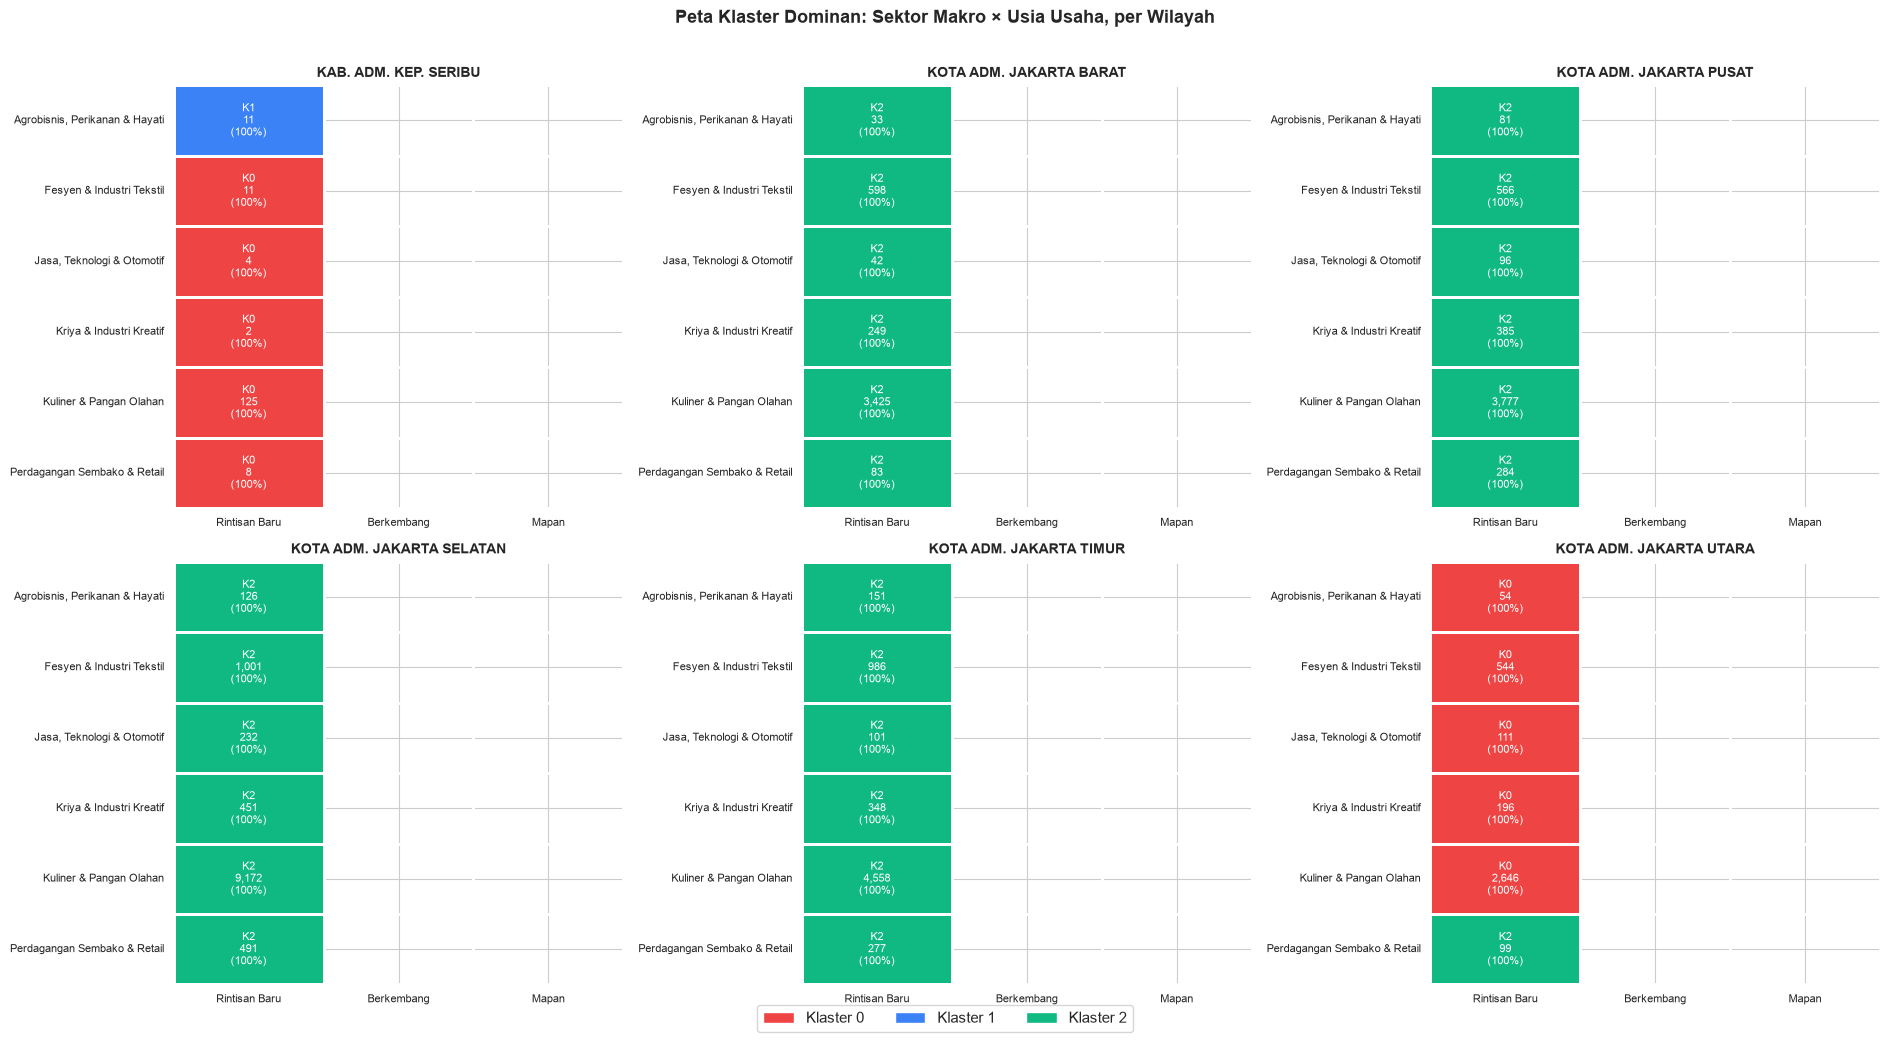

Sel abu-abu/"-" = tidak ada UMKM pada kombinasi sektor x usia usaha tsb di wilayah itu.


In [7]:
K_FINAL = 3
CLUSTER_COLORS = ['#EF4444', '#3B82F6', '#10B981']  # selaras dengan warna kartu profil klaster di app.py

usia_order = ['Rintisan Baru (2024)', 'Berkembang (2022-2023)', 'Mapan (2020-2021)']
sektor_order = sorted(df['sektor_makro'].unique().tolist())

def build_cluster_heatmap_data(df_region, sektor_order, usia_order):
    """Crosstab sektor_makro x kelompok_tahun_berdiri -> klaster dominan + jumlah + persentase."""
    grouped = df_region.groupby(['sektor_makro', 'kelompok_tahun_berdiri'])['cluster']
    dominan = grouped.agg(lambda s: s.mode().iloc[0] if len(s) else np.nan).rename('cluster_dominan')
    n_total = grouped.size().rename('n')
    n_dominan = grouped.agg(lambda s: s.value_counts().iloc[0] if len(s) else 0).rename('n_dominan')
    tbl = pd.concat([dominan, n_total, n_dominan], axis=1).reset_index()
    tbl['pct_dominan'] = (tbl['n_dominan'] / tbl['n'] * 100).round(1)

    pivot_cluster = tbl.pivot(index='sektor_makro', columns='kelompok_tahun_berdiri', values='cluster_dominan').reindex(index=sektor_order, columns=usia_order)
    pivot_n = tbl.pivot(index='sektor_makro', columns='kelompok_tahun_berdiri', values='n').reindex(index=sektor_order, columns=usia_order)
    pivot_pct = tbl.pivot(index='sektor_makro', columns='kelompok_tahun_berdiri', values='pct_dominan').reindex(index=sektor_order, columns=usia_order)
    return pivot_cluster, pivot_n, pivot_pct


fig, axes = plt.subplots(2, 3, figsize=(19, 10))
axes = axes.flatten()
cmap = ListedColormap(CLUSTER_COLORS[:K_FINAL])

for idx, wil in enumerate(daftar_wilayah):
    df_wil = df[df['wilayah'] == wil]
    pivot_cluster, pivot_n, pivot_pct = build_cluster_heatmap_data(df_wil, sektor_order, usia_order)

    annot = np.empty(pivot_cluster.shape, dtype=object)
    baris_teks = pivot_cluster.shape[0]
    kolom_teks = pivot_cluster.shape[1]
    for r in range(baris_teks):
        for c in range(kolom_teks):
            if pd.isna(pivot_cluster.iat[r, c]):
                annot[r, c] = "-"
            else:
                baris = [
                    f"K{int(pivot_cluster.iat[r, c])}",
                    f"{int(pivot_n.iat[r, c]):,}",
                    f"({pivot_pct.iat[r, c]:.0f}%)",
                ]
                annot[r, c] = chr(10).join(baris)

    mask = pivot_cluster.isna()
    sns.heatmap(
        pivot_cluster.astype(float), mask=mask, annot=annot, fmt='', cmap=cmap,
        vmin=-0.5, vmax=K_FINAL - 0.5, cbar=False, linewidths=1, linecolor='white',
        ax=axes[idx], annot_kws={'fontsize': 8}, xticklabels=[u.split(' (')[0] for u in usia_order]
    )
    axes[idx].set_title(wil, fontsize=10, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('')
    axes[idx].tick_params(axis='y', rotation=0, labelsize=8)
    axes[idx].tick_params(axis='x', rotation=0, labelsize=8)

legend_patches = [Patch(facecolor=CLUSTER_COLORS[k], label=f'Klaster {k}') for k in range(K_FINAL)]
fig.legend(handles=legend_patches, loc='lower center', ncol=K_FINAL, bbox_to_anchor=(0.5, -0.02), fontsize=11)
fig.suptitle('Peta Klaster Dominan: Sektor Makro × Usia Usaha, per Wilayah', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print('Sel abu-abu/"-" = tidak ada UMKM pada kombinasi sektor x usia usaha tsb di wilayah itu.')


**Interpretasi (Jakarta Selatan):** `freq_dist` (frekuensi `sektor_makro` saja, digabung lintas semua usia usaha) menunjukkan **Kuliner & Pangan Olahan** menyumbang 71,06% populasi UMKM — tanpa informasi apa pun soal kapan usaha-usaha itu berdiri. Profil klaster 2-fitur mengungkap sesuatu yang tidak terlihat dari angka gabungan itu: proporsi Kuliner & Pangan Olahan ternyata **bergeser konsisten menurut usia usaha** — 68,3% di antara usaha **Klaster 0** (Mapan 2020-2021, 100% anggotanya), naik ke 71,7% di **Klaster 1** (Berkembang 2022-2023, 100%), dan naik lagi ke 79,9% di **Klaster 2** (Rintisan Baru 2024, 100%, 16,5% populasi). Semakin baru usaha berdiri, semakin terkonsentrasi pada sektor Kuliner & Pangan Olahan dibanding usaha yang lebih lama — tren yang tersembunyi di balik angka `freq_dist` gabungan.

Contoh lain lintas wilayah: **Klaster 2 di Jakarta Utara** (10,4% populasi wilayah tsb) adalah satu-satunya klaster di seluruh 6 wilayah yang dominan sektornya BUKAN Kuliner & Pangan Olahan, melainkan **Perdagangan Sembako & Retail (100% murni)**, dengan 97,9% anggotanya berusia Mapan (2020-2021) — sebuah segmen usaha ritel/sembako lama yang berbeda karakter dari mayoritas klaster kuliner di wilayah-wilayah lain. Pola co-occurrence sektor × usia usaha seperti ini — baik tren pergeseran proporsi antar usia (Jakarta Selatan) maupun pengecualian sektor per wilayah (Jakarta Utara) — adalah nilai tambah utama clustering 2 atribut dibanding sekadar `value_counts()` satu atribut, dan divisualisasikan secara lengkap untuk seluruh 6 wilayah pada heatmap Bagian 7 di bawah.

## 6. Penyimpanan Rekapitulasi Hasil Interpretasi
Menyimpan tabel profil klaster final ($k=3$) ke `data/processed/03_kmodes_evaluation_summary.csv` -- lengkap dengan Location Quotient (LQ) dan label Red/Neutral/Blue Ocean per klaster per wilayah, siap dipakai langsung oleh `app.py` untuk kartu profil klaster.

In [8]:
eval_out = os.path.join('..', 'data', 'processed', '03_kmodes_evaluation_summary.csv')
profile_df.to_csv(eval_out, index=False)

print(f"Hasil profil klaster & klasifikasi Ocean berhasil disimpan di: {eval_out}")

Hasil profil klaster & klasifikasi Ocean berhasil disimpan di: ..\data\processed\03_kmodes_evaluation_summary.csv
